# 2.6 Data Visualization

**Goal:** select and interpret ten common chart types for EDA, including their assumptions and failure modes.

**Prerequisites:** the earlier Module 2 notebooks. **Runtime:** Python 3.10+ and Matplotlib (`python3 -m pip install matplotlib` in your chosen environment). All data are synthetic and generated locally. Ten saved figures are embedded, so the notebook can be read without running it. Run cells in order to reproduce the examples.

## Contents
1. Bar charts
2. Pie charts
3. Histograms
4. Frequency polygons
5. Box plots
6. Violin plots
7. Density plots
8. Scatter plots
9. Line charts
10. Heatmaps
11. Chart selection and an EDA workflow
12. Practice and solutions

## Setup and plotting principles

Choose the chart from the question and variable types, not appearance. Label axes and units, specify the observational unit and denominator, and explain transformations, binning, normalization, or smoothing. Use readable colors and labels; do not rely only on red/green distinctions.

When comparing groups, use compatible axes, bins, and normalization, and show group sizes. An attractive chart can still mislead through truncated bar baselines, hidden missing records, cherry-picked time ranges, or unequal exposure. These figures describe synthetic samples and do not make causal or population claims.

In [1]:
import math
import random
import statistics
from collections import Counter
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 13,
                     "axes.labelsize": 11, "font.size": 10})
rng = random.Random(2026)
latency_ms = [rng.lognormvariate(4.0, 0.55) for _ in range(240)]
group_a = [rng.gauss(50, 8) for _ in range(80)]
group_b = [rng.gauss(45, 5) for _ in range(40)] + [rng.gauss(65, 5) for _ in range(40)]
print("Synthetic latency observations:", len(latency_ms))
print("Comparison groups:", len(group_a), len(group_b))

Synthetic latency observations: 240
Comparison groups: 80 80


## 1. Bar Charts

A bar chart compares counts, proportions, or another summary across discrete categories. Separate bars emphasize category identity; for ordinal categories preserve natural order. Bar length encodes magnitude, so a zero baseline is normally necessary for honest magnitude comparisons.

**Worked example:** counts of web, mobile, and phone tickets reveal the channel mix. Displaying the same bars as percentages would describe shares of the observed total, not necessarily shares of all eligible tickets if channels were omitted from collection.

Bar charts differ from histograms: a bar represents a category, whereas histogram intervals cover a numerical axis. If bars show means rather than counts, label them and consider uncertainty and within-group distribution rather than hiding everything behind one height.

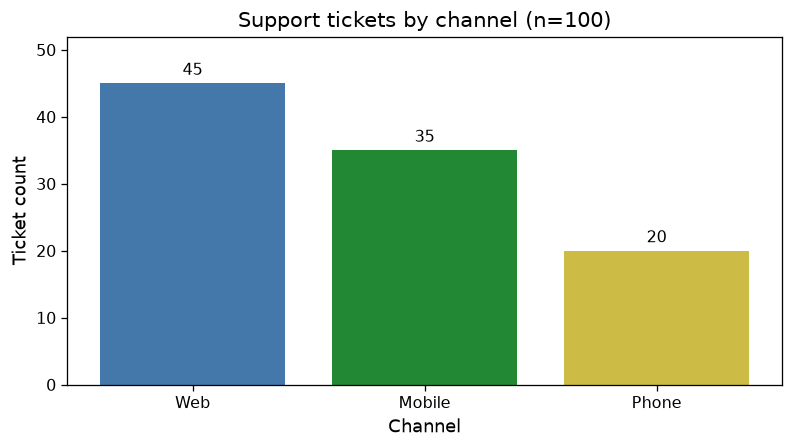

In [2]:
channels = {"Web": 45, "Mobile": 35, "Phone": 20}
fig, ax = plt.subplots()
bars = ax.bar(list(channels), list(channels.values()), color=["#4477AA", "#228833", "#CCBB44"])
ax.bar_label(bars, padding=3)
ax.set(title="Support tickets by channel (n=100)", xlabel="Channel", ylabel="Ticket count", ylim=(0, 52))
fig.tight_layout()
plt.show()

## 2. Pie Charts

A pie chart shows parts of a meaningful whole. Categories should be mutually exclusive and exhaustive; shares must use the same denominator. It works best with few categories and large differences. A bar chart is often easier for comparing similar shares or many categories.

**Worked example:** the same 100 tickets form 45%, 35%, and 20% channel shares. These are not three independently normalized statistics. Do not use pie slices for overlapping labels, negative quantities, or unrelated rates. Avoid 3D effects, which distort perceived areas.

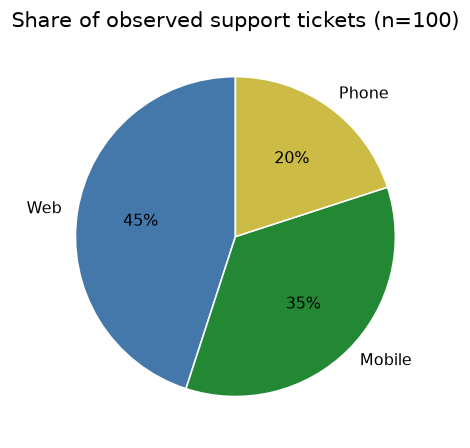

In [3]:
fig, ax = plt.subplots()
ax.pie(list(channels.values()), labels=list(channels), autopct="%1.0f%%", startangle=90,
       colors=["#4477AA", "#228833", "#CCBB44"], wedgeprops={"edgecolor": "white"})
ax.set_title("Share of observed support tickets (n=100)")
ax.set_aspect("equal")
fig.tight_layout()
plt.show()

## 3. Histograms

A histogram groups numerical observations into adjacent intervals. For equal-width bins, count heights show frequency per interval. With density normalization, height is $f_j/(n\times\text{width}_j)$, and bin area is relative frequency; the total area is 1. Density height is not a point probability and can exceed 1.

**Worked example:** response latencies show a right tail. These bins cover every generated latency; their left edges are included and right edges excluded, except the final bin includes its rightmost endpoint. Bin choices can reveal or obscure apparent peaks. When comparing groups, reuse boundaries and consider normalizing when sample sizes differ.

Unequal-width count bars can mislead because wide intervals naturally contain more observations. Use density heights if interpreting bar area as relative frequency. Missing observations are not zero-latency values.

Histogram total area: 1.0


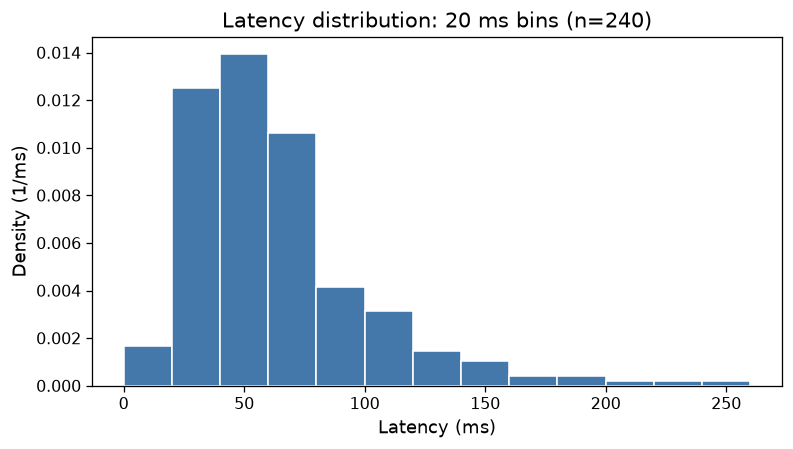

In [4]:
upper_edge = math.ceil(max(latency_ms)/20)*20
latency_edges = list(range(0, upper_edge+1, 20))
fig, ax = plt.subplots()
heights, used_edges, _ = ax.hist(latency_ms, bins=latency_edges, density=True,
                               color="#4477AA", edgecolor="white")
area = sum(float(h)*(float(b)-float(a)) for h, a, b in zip(heights, used_edges, used_edges[1:]))
ax.set(title="Latency distribution: 20 ms bins (n=240)", xlabel="Latency (ms)", ylabel="Density (1/ms)")
fig.tight_layout()
print("Histogram total area:", round(area, 12))
assert math.isclose(area, 1, abs_tol=1e-12)
plt.show()

## 4. Frequency Polygons

A frequency polygon places a point at each class midpoint and joins the points with straight lines. It summarizes the same binned frequencies as a histogram. With equal-width bins, it can compare distribution shapes without overlapping bars. If comparing different sample sizes, use relative frequencies or densities with clearly labeled units.

**Worked example:** midpoint counts from the preceding latency bins show the rise and fall across classes. Endpoints at zero one class-width beyond the outer midpoints are a conventional visual closure, not extra observed classes. If widths differ, do not equate midpoint count heights with a probability density.

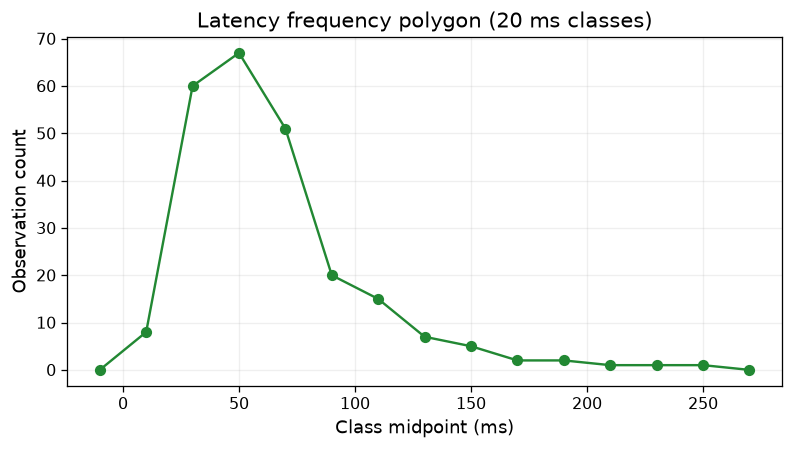

In [5]:
# Reuse exact histogram boundaries; final right endpoint belongs to the last bin.
bin_counts = [0]*(len(latency_edges)-1)
for value in latency_ms:
    index = min(int(value//20), len(bin_counts)-1)
    bin_counts[index] += 1
midpoints = [(a+b)/2 for a, b in zip(latency_edges, latency_edges[1:])]
fig, ax = plt.subplots()
ax.plot([midpoints[0]-20]+midpoints+[midpoints[-1]+20], [0]+bin_counts+[0],
        marker="o", color="#228833")
ax.set(title="Latency frequency polygon (20 ms classes)", xlabel="Class midpoint (ms)", ylabel="Observation count")
ax.grid(alpha=0.2)
fig.tight_layout()
assert sum(bin_counts) == len(latency_ms)
plt.show()

## 5. Box Plots

A box plot summarizes median, quartiles, and tails compactly. Here the box spans $Q_1$ to $Q_3$, the interior line is the median, and whiskers reach the most extreme observed values within 1.5-IQR fences. Points beyond those whiskers are displayed individually; they are not automatically mistakes.

**Worked example:** groups A and B have similar central ranges but different internal structure. Box plots can conceal multiple peaks and sample sizes, so labels show n=80 per group. Their whiskers do not automatically equal the dataset minimum and maximum.

The Matplotlib default percentile interpolation used here matches the type-7 numerical convention described earlier. Treat a box plot as a summary, not a full distribution view.

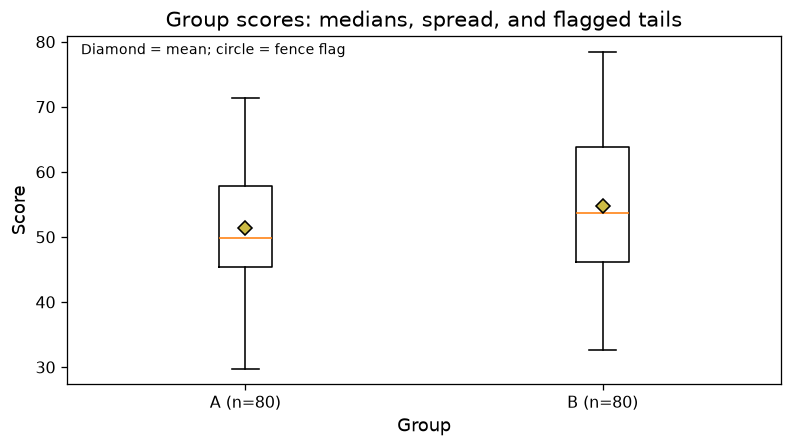

In [6]:
fig, ax = plt.subplots()
ax.boxplot([group_a, group_b], tick_labels=["A (n=80)", "B (n=80)"], whis=1.5,
           showmeans=True, meanprops={"marker": "D", "markerfacecolor": "#CCBB44", "markeredgecolor": "black"})
ax.set(title="Group scores: medians, spread, and flagged tails", xlabel="Group", ylabel="Score")
ax.text(0.02, 0.98, "Diamond = mean; circle = fence flag", transform=ax.transAxes, va="top", fontsize=9)
fig.tight_layout()
plt.show()

## 6. Violin Plots

A violin plot mirrors a smoothed density estimate around a group axis. Wider parts indicate greater estimated density, not necessarily more total observations; many libraries normalize violin widths independently. It can expose multiple peaks hidden by a box plot, but its shape depends on smoothing bandwidth and sample size.

**Worked example:** group B was generated from two score clusters; the violin can suggest this structure. The plot does not prove that real latent subgroups exist, and a small sample can create unstable apparent peaks. Quartile markers and group counts add reference information.

Default smoothing can extend beyond plausible support in some implementations; inspect boundaries and document any clipping. Do not assume every violin implementation uses identical bandwidth or width normalization.

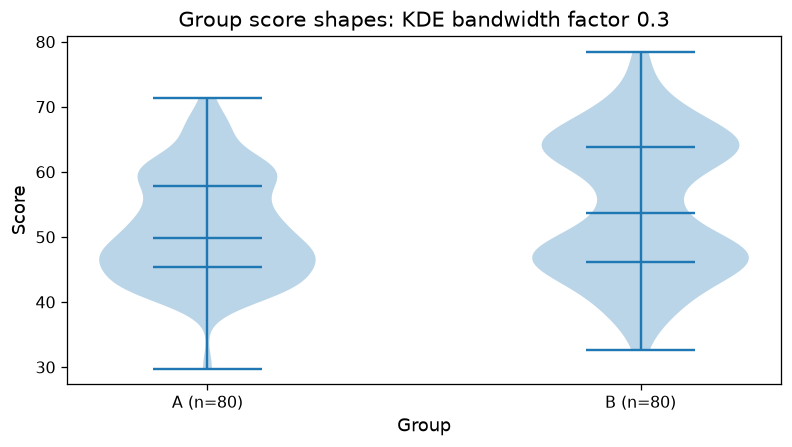

In [7]:
fig, ax = plt.subplots()
ax.violinplot([group_a, group_b], positions=[1, 2], showmedians=True,
              quantiles=[[0.25, 0.75], [0.25, 0.75]], bw_method=0.3)
ax.set_xticks([1, 2], ["A (n=80)", "B (n=80)"])
ax.set(title="Group score shapes: KDE bandwidth factor 0.3", xlabel="Group", ylabel="Score")
fig.tight_layout()
plt.show()

## 7. Density Plots

A kernel density estimate (KDE) places a smooth kernel at each observation and averages them. For a Gaussian kernel with bandwidth $h>0$:
$$\hat f(x)=\frac1{nh\sqrt{2\pi}}\sum_i\exp\left(-\frac12\left(\frac{x-x_i}{h}\right)^2\right).$$

The complete density integrates to 1. A curve evaluated on a finite display grid shows only part of its support. Small bandwidths create wiggles; large bandwidths can hide meaningful structure. KDE is an estimate, not direct evidence of an exact population density.

**Worked example:** bandwidths of 3 and 10 score units produce different smoothness for the same group B data. A Gaussian KDE can assign density below a natural zero boundary; use boundary-aware methods or a justified transform for constrained variables. Compare bandwidth choices and sample sizes before interpreting bumps.

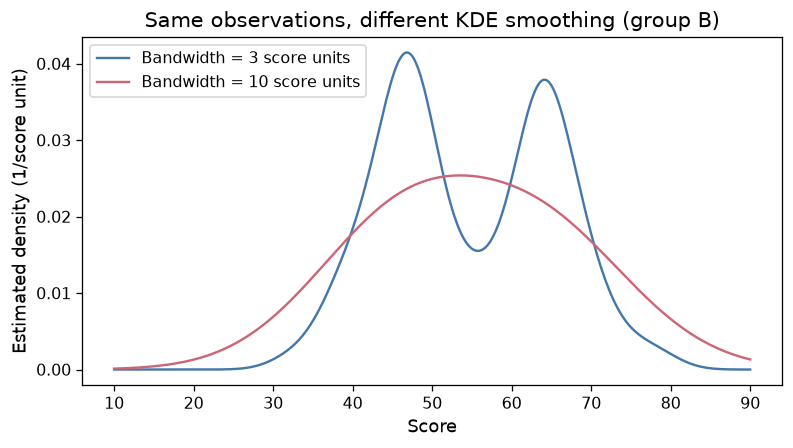

In [8]:
def gaussian_kde_at(x, values, bandwidth):
    if bandwidth <= 0 or not values:
        raise ValueError("Need positive bandwidth and nonempty data")
    return sum(math.exp(-0.5*((x-v)/bandwidth)**2) for v in values)/(len(values)*bandwidth*math.sqrt(2*math.pi))

grid = [10+i*0.25 for i in range(321)]
fig, ax = plt.subplots()
for bandwidth, color in [(3, "#4477AA"), (10, "#CC6677")]:
    ax.plot(grid, [gaussian_kde_at(x, group_b, bandwidth) for x in grid],
            label=f"Bandwidth = {bandwidth} score units", color=color)
ax.set(title="Same observations, different KDE smoothing (group B)", xlabel="Score", ylabel="Estimated density (1/score unit)")
ax.legend()
fig.tight_layout()
plt.show()

## 8. Scatter Plots

A scatter plot shows paired numerical observations, one point per unit. It reveals direction, nonlinear relationships, clusters, varying spread, and joint outliers. Color or symbol can encode a third variable, but too many encodings reduce readability. With many repeated/overlapping points, transparency, small markers, aggregation, or an explicitly documented jitter can help.

**Worked example:** synthetic study hours and scores are positively associated. The observed pattern alone would not prove the causal effect of additional study; background preparation could affect both variables. Always align pairs correctly after cleaning or joins.

A straight fitted line can hide nonlinear relationships or different subgroup patterns. Inspect points rather than reporting only a correlation coefficient.

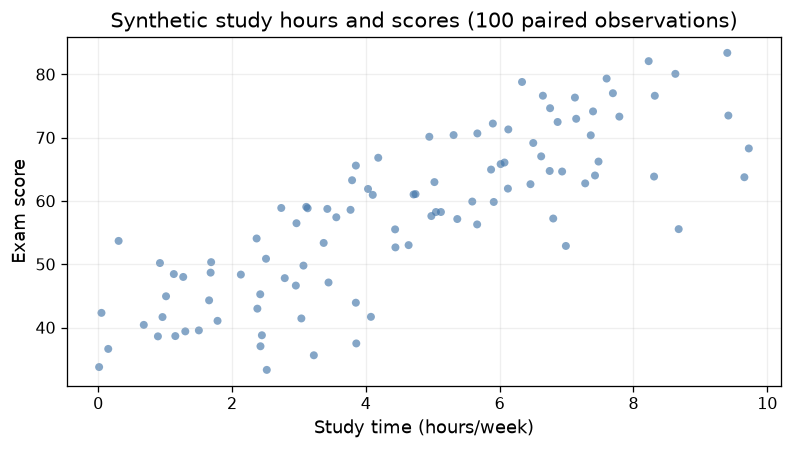

In [9]:
hours = [rng.uniform(0, 10) for _ in range(100)]
scores = [40+4*h+rng.gauss(0, 7) for h in hours]
fig, ax = plt.subplots()
ax.scatter(hours, scores, alpha=0.65, s=25, color="#4477AA", edgecolors="none")
ax.set(title="Synthetic study hours and scores (100 paired observations)", xlabel="Study time (hours/week)", ylabel="Exam score")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 9. Line Charts

A line chart joins observations in meaningful order, most often time. Sort timestamps first, respect unequal spacing, and consider showing gaps when observations are missing. Lines suggest continuity between points; do not connect nominal categories in an arbitrary order as if they were a time process.

**Worked example:** daily demand shows a trend with a recurring weekly pattern in synthetic data. Time dependence matters when splitting training and evaluation records. For multiple series, consistent scales or clearly labeled separate panels help avoid misleading comparisons.

Smoothing can aid visibility but can hide spikes and may use future observations. For forecasting features, a centered moving average would leak future information; a trailing average should use only past values available at prediction time.

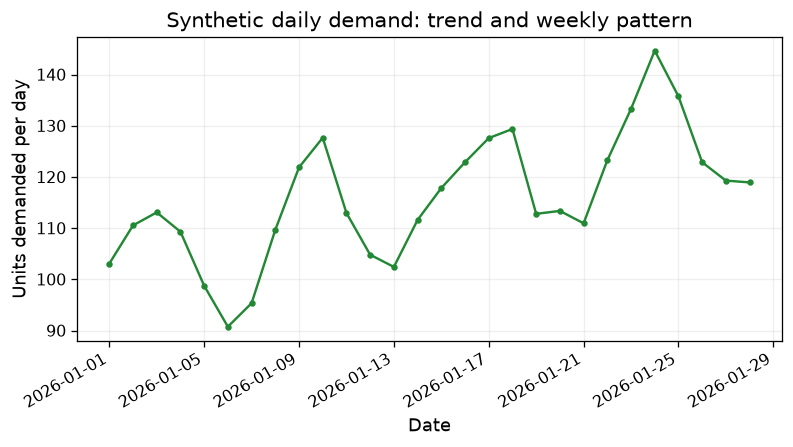

In [10]:
from datetime import date, timedelta
dates = [date(2026, 1, 1)+timedelta(days=i) for i in range(28)]
demand = [100+1.2*i+12*math.sin(2*math.pi*i/7)+rng.gauss(0, 3) for i in range(28)]
fig, ax = plt.subplots()
ax.plot(dates, demand, marker="o", markersize=3, color="#228833")
ax.set(title="Synthetic daily demand: trend and weekly pattern", xlabel="Date", ylabel="Units demanded per day")
fig.autofmt_xdate()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 10. Heatmaps

A heatmap maps a matrix of values to colors. Common uses include a correlation matrix, a confusion matrix, or a missingness grid. Label rows and columns, include a color bar with the quantity represented, and choose a color scale suited to the values. Use a diverging scale centered at zero for signed correlations and a sequential scale for nonnegative counts.

**Worked example:** this correlation heatmap compares hours, practice attempts, and score. Pearson correlations describe linear association, require nonconstant paired variables, and range from -1 to 1. Fixing those color limits supports comparisons across charts. Strong correlation is not causation; near-zero correlation does not rule out nonlinear association.

Missing values require a deliberate pairwise/complete-case policy and can produce cells based on different sample sizes. The complete synthetic table below avoids that issue. For classification confusion matrices, row-normalized and raw-count heatmaps answer different questions; label the normalization.

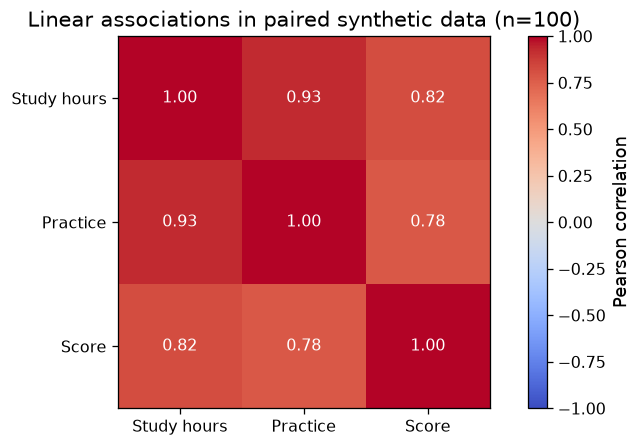

In [11]:
practice = [2*h+rng.gauss(0, 2) for h in hours]
series = [hours, practice, scores]
names = ["Study hours", "Practice", "Score"]
def pearson(x, y):
    if len(x) != len(y) or len(x) < 2:
        raise ValueError("Need paired observations")
    mx, my = statistics.mean(x), statistics.mean(y)
    numerator = sum((a-mx)*(b-my) for a, b in zip(x, y))
    denominator = math.sqrt(sum((a-mx)**2 for a in x)*sum((b-my)**2 for b in y))
    if denominator == 0:
        raise ValueError("Correlation undefined for constant variables")
    return numerator/denominator

matrix = [[pearson(a, b) for b in series] for a in series]
fig, ax = plt.subplots()
image = ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(3), names)
ax.set_yticks(range(3), names)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{matrix[i][j]:.2f}", ha="center", va="center",
                color="white" if abs(matrix[i][j]) > 0.6 else "black")
fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Linear associations in paired synthetic data (n=100)")
fig.tight_layout()
assert all(math.isclose(matrix[i][i], 1, abs_tol=1e-12) for i in range(3))
plt.show()

## 11. Choosing a chart for EDA

| Question | Chart | Key caution |
|---|---|---|
| How frequent is each category? | Bar | Baseline, denominator, missing levels |
| How do a few parts make a whole? | Pie | Exhaustive nonoverlapping categories |
| What is a numeric distribution? | Histogram | Binning and density normalization |
| How do binned shapes compare? | Frequency polygon | Shared bins and appropriate normalization |
| How do center and spread differ? | Box | Hidden multimodality and whisker rule |
| What within-group shapes appear? | Violin | Bandwidth, small samples, normalization |
| What smooth density shape is estimated? | Density/KDE | Bandwidth and boundary artifacts |
| How are paired numbers related? | Scatter | Overplotting and confounding |
| How does a variable change over time? | Line | Ordering, gaps, temporal dependence |
| What pattern exists across a matrix? | Heatmap | Color limits, quantity, normalization |

A practical EDA sequence is to audit row units and missingness, plot category counts and numerical distributions, inspect paired relationships and temporal trends, compare important subgroups, and then investigate unusual cases. Descriptive charts generate questions and guide preprocessing; they do not replace independent validation.

For ML, use plots to inspect class imbalance, plan scaling, compare missing-value imputation effects, and review outlier policies. Compare distributions before and after transformations, keeping axes and definitions clear. Avoid repeatedly tuning on a final test set; use training/validation data for iterative exploration and reserve test evaluation for the final procedure.

## Practice

1. Choose a chart for browser counts, response-time distribution, paired age/income, and weekly revenue.
2. Why should an ordinary bar chart normally begin at zero?
3. A density histogram bar has height 0.1 and width 4. What relative frequency does its area represent?
4. Do box-plot whiskers always reach the observed min and max?
5. Why can two KDE bandwidths suggest different numbers of peaks for identical observations?
6. Can pie slices represent overlapping product tags without additional processing?
7. Why is a sequential heatmap palette inappropriate for emphasizing positive and negative correlations around zero?
8. What information should accompany a plot comparing two group distributions?
9. Does a rising time series justify a causal claim about a policy introduced during that period?
10. Why is a scatter plot useful even when Pearson correlation is near zero?

## Solutions

1. Bar; histogram/density; scatter; time-ordered line chart.
2. Bar length encodes magnitude; a truncated baseline exaggerates ratios and differences in lengths.
3. $0.1\times4=0.4$, or 40%, assuming the density-normalized histogram covers the included sample.
4. No. With Tukey whiskers they reach the most extreme observed values inside the 1.5-IQR fences; outlying points are separate.
5. Smoothing changes local detail: too little can overfit noise; too much can merge genuine modes. Peaks need context and sensitivity checks.
6. No. Slices must partition one whole. Overlapping memberships double count and require another representation or a redefined partition.
7. A diverging palette centered at zero makes the two directions distinct and equally referenced. A sequential palette is designed for ordered magnitude in one direction.
8. Group sizes, units, shared bins/scales where appropriate, normalization, missing-data exclusions, and any smoothing or transformation choices.
9. No. Trend, seasonality, confounding events, or measurement changes can explain a coincident change. Causal inference needs a suitable design and assumptions.
10. It can reveal nonlinear patterns, subgroups, or outliers hidden by a single linear correlation summary.

**Readiness check:** explain what each axis, mark, and color represents, state the denominator or normalization, and identify at least one way a chart could mislead.

**Next:** Module 3 — Probability Theory in the [main syllabus](../README.md).